# Анализ данных и физические гипотезы


## Происхождение данных

В работе используется набор данных Wave Energy Converters, опубликованный в UCI Machine Learning Repository.

Данные получены в результате численного гидродинамического моделирования и оптимизации пространственного расположения 16 преобразователей волновой энергии.

Рассматриваются четыре волновых сценария: Sydney, Adelaide, Perth и Tasmania.

Каждое наблюдение соответствует одной конфигурации массива преобразователей и содержит информацию об их координатах, индивидуальных мощностях и суммарной поглощённой мощности.

Источник: https://archive.ics.uci.edu/dataset/494/wave+energy+converters

### Физический смысл и размерности исходных данных

Каждое наблюдение соответствует одной пространственной конфигурации волновой фермы, состоящей из 16 преобразователей волновой энергии (Wave Energy Converters, WEC).

Входные переменные представляют собой декартовы координаты преобразователей в горизонтальной плоскости, выраженные в метрах. Область размещения имеет размеры 566 × 566 м.

Целевая переменная `Powerall` представляет собой суммарную поглощённую мощность массива преобразователей, выраженную в ваттах.

Индивидуальные мощности `P1`–`P16` исключаются из пространства входных признаков во избежание утечки целевой информации.

Значения мощности получены посредством численного гидродинамического моделирования, а не непосредственных экспериментальных измерений.

**Источники:**
1. Neshat, M., Wagner, M., & Alexander, B. (2018).
   Wave Energy Converters [Dataset].
   UCI Machine Learning Repository.
   https://doi.org/10.24432/C5831S



In [13]:
from pathlib import Path
import sys 

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'

sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_dataset

from src.validation import validate_dataset


In [14]:
scenarios = ["Sydney", "Adelaide", "Perth", "Tasmania"]

datasets = {
    scenario: load_dataset(scenario)
    for scenario in scenarios
}

In [15]:
validation_results = pd.DataFrame({
    scenario: validate_dataset(data)
    for scenario, data in datasets.items()
}).T

display(validation_results.T)

,Sydney,Adelaide,Perth,Tasmania
rows,72000.000000,71999.000000,7.200000e+04,72000.000000
columns,49.000000,49.000000,4.900000e+01,49.000000
missing_values,0.000000,0.000000,0.000000e+00,0.000000
infinite_values,0.000000,0.000000,0.000000e+00,0.000000
duplicate_rows,27174.000000,0.000000,2.420000e+02,0.000000
duplicate_layouts,27174.000000,0.000000,2.430000e+02,0.000000
min_coordinate,-0.034500,0.000000,0.000000e+00,0.000000
max_coordinate,566.000800,566.000000,5.660000e+02,566.000000
invalid_coordinates,6.000000,0.000000,0.000000e+00,0.000000
negative_individual_power,0.000000,0.000000,0.000000e+00,0.000000


### Повторяющиеся наблюдения

Наиболее существенной статистической особенностью исходных данных является наличие большого количества повторяющихся наблюдений в сценарии Sydney: 27 174 точных дубликата, составляющих 37,74% выборки.

В сценарии Perth обнаружено 242 точных дубликата и 243 повторения координатных конфигураций. В остальных сценариях точные дубликаты отсутствуют.

Наличие повторений может быть связано с особенностями эволюционных алгоритмов оптимизации, использованных при генерации данных.

При случайном разделении выборки повторяющиеся конфигурации могут одновременно попадать в обучающую и проверочную части, приводя к завышению оценок прогностического качества.

Поэтому на последующих этапах исследования необходимо учитывать геометрическую идентичность конфигураций при разделении данных. Окончательный способ обработки повторений будет определён при построении вычислительного эксперимента.

In [16]:
sydney_df = datasets['Sydney']

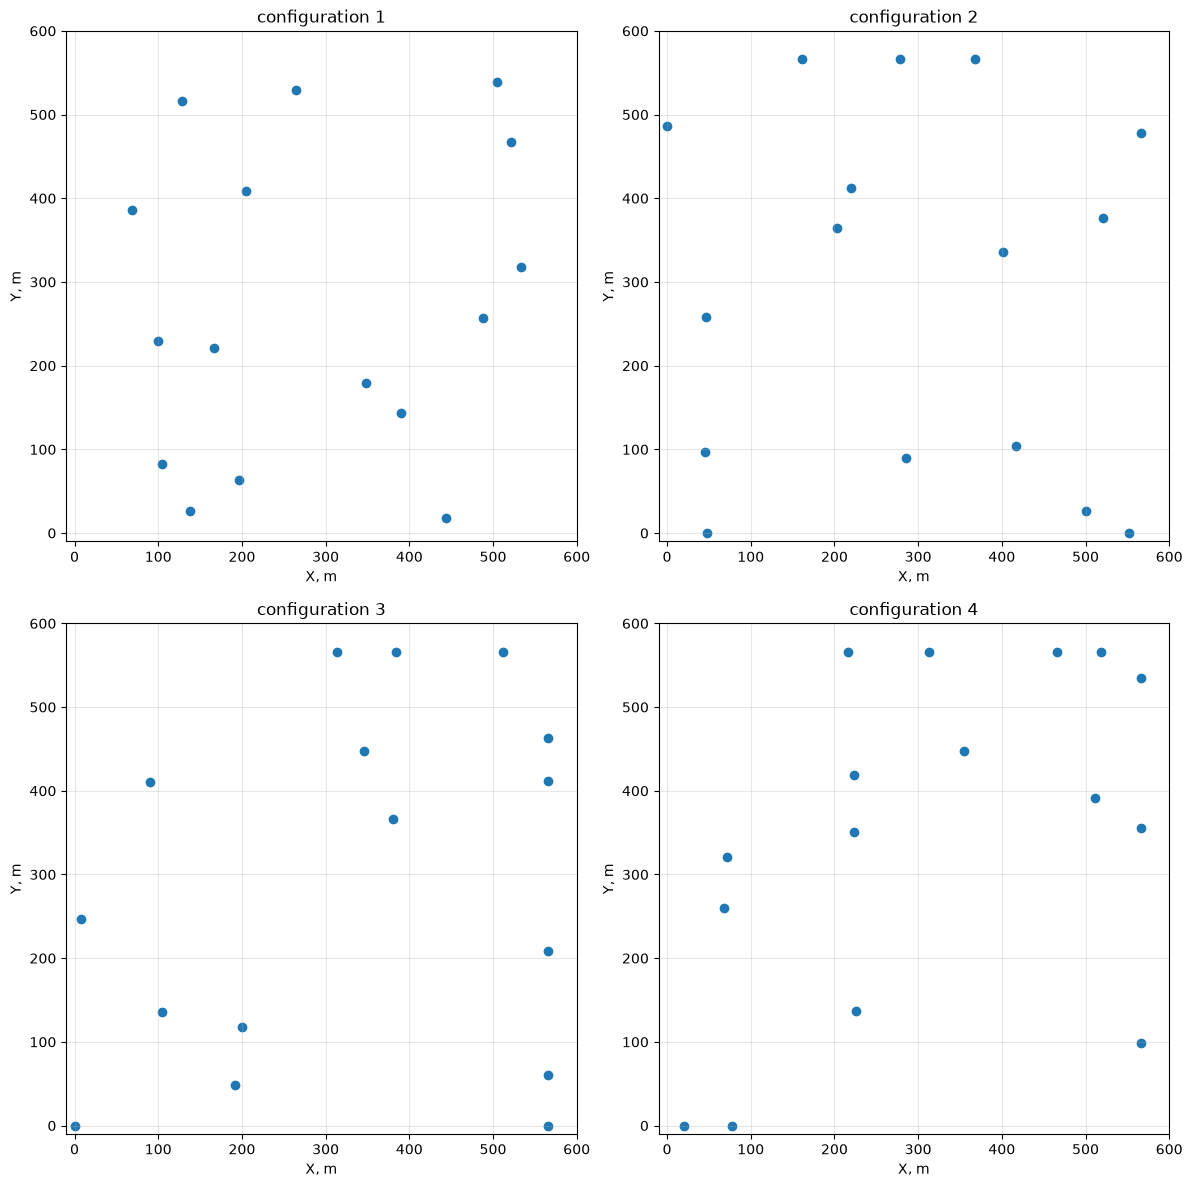

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12,12))

x_coords = sydney_df[[f'X{i}' for i in range(1, 17)]]
y_coords = sydney_df[[f'Y{i}' for i in range(1, 17)]]

for i, ax in enumerate(axes.flat):
    x = x_coords.iloc[i]
    y = y_coords.iloc[i]

    ax.scatter(x, y)
    ax.set_title(f'configuration {i + 1}')
    ax.set_xlim(-10, 600)
    ax.set_ylim(-10, 600)
    ax.set_xlabel("X, m")
    ax.set_ylabel("Y, m")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


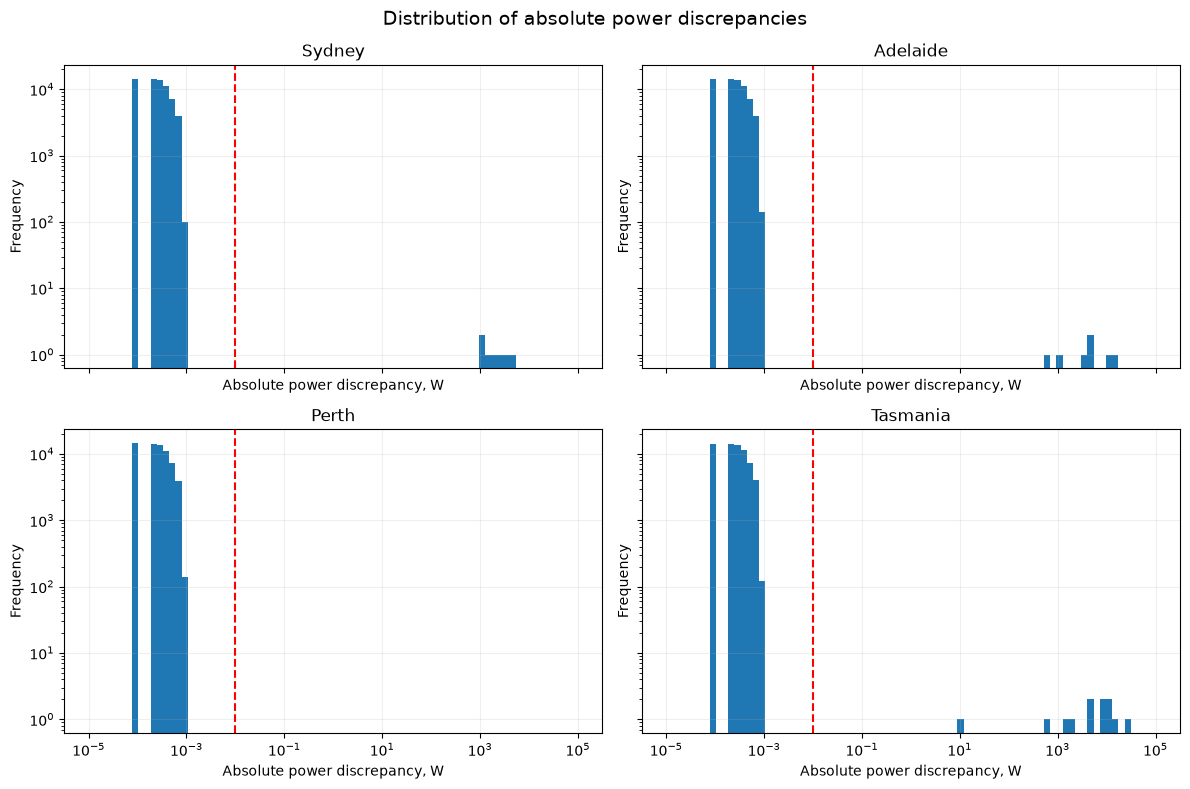

In [18]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

bins = np.logspace(-5, 5, 80)

for ax, (scenario, df) in zip(axes.flat, datasets.items()):

    error = (
        df["Powerall"] - df.iloc[:, 32:48].sum(axis=1)
    ).abs()

    ax.hist(error[error > 0], bins=bins)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(0.01, linestyle="--", color="red")

    ax.set_title(scenario)
    ax.set_xlabel("Absolute power discrepancy, W")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)
    
fig.suptitle(
    "Distribution of absolute power discrepancies",
    fontsize=14
)
plt.tight_layout()
plt.show()

### Анализ распределения расхождений мощности

Распределения абсолютных расхождений между суммарной мощностью и суммой индивидуальных мощностей имеют практически одинаковую структуру в области малых значений для всех четырёх волновых сценариев.

Основная масса наблюдений характеризуется расхождениями порядка 0,0001–0,001 Вт, что согласуется с погрешностью округления исходных данных.

В сценариях Sydney, Adelaide и Tasmania также присутствуют отдельные наблюдения с расхождениями на несколько порядков выше. Между основным распределением и аномальными значениями наблюдается выраженный разрыв.

Всего обнаружено 26 таких наблюдений, составляющих приблизительно 0,009% исходного набора данных.

На основании наблюдаемого распределения в качестве диагностического порога несогласованности мощностей принимается значение 0,01 Вт.

Причины возникновения крупных расхождений остаются неизвестными. Поэтому автоматически пересчитывать целевую переменную Powerall на основании индивидуальных мощностей нецелесообразно.

In [19]:
from scipy.spatial.distance import pdist

anomalies = []

for scenario, df in datasets.items():

    power_sum = df.iloc[:, 32:48].sum(axis=1)
    error = df["Powerall"] - power_sum

    mask = error.abs() > 0.01

    for idx, row in df.loc[mask].iterrows():

        x = row.iloc[:16].to_numpy(dtype=float)
        y = row.iloc[16:32].to_numpy(dtype=float)

        coords = np.column_stack((x, y))

        min_distance = pdist(coords).min()

        anomalies.append({
            "scenario": scenario,
            "row_id": idx,
            "min_distance_m": min_distance,
            "distance_violation": min_distance < 50,
            "Powerall": row["Powerall"],
            "power_sum": power_sum.loc[idx],
            "signed_error_W": error.loc[idx],
            "absolute_error_W": abs(error.loc[idx])
        })

anomaly_report = pd.DataFrame(anomalies)

display(anomaly_report)

,scenario,row_id,min_distance_m,distance_violation,Powerall,power_sum,signed_error_W,absolute_error_W
0,Sydney,32885,53.859432,False,1507456.524,1.506439e+06,1017.5978,1017.5978
1,Sydney,32887,57.499573,False,1499878.581,1.498331e+06,1547.3767,1547.3767
2,Sydney,32889,61.681801,False,1499558.969,1.497377e+06,2181.5721,2181.5721
3,Sydney,32893,53.654319,False,1510422.778,1.506223e+06,4199.4745,4199.4745
4,Sydney,32895,59.878738,False,1511318.810,1.510285e+06,1033.9690,1033.9690
5,Sydney,32899,68.929741,False,1505826.099,1.501785e+06,4040.7771,4040.7771
6,Sydney,32902,68.956591,False,1475880.566,1.472881e+06,2999.9571,2999.9571
7,Adelaide,61267,50.005400,False,1488143.658,1.483191e+06,4953.0685,4953.0685
8,Adelaide,61271,50.000818,False,1505563.865,1.488627e+06,16937.2387,16937.2387
9,Adelaide,61273,58.566117,False,1490226.290,1.485987e+06,4239.6508,4239.6508


### Исследование природы аномальных расхождений

Во всех 26 аномальных конфигурациях минимальное попарное расстояние между преобразователями превышает 50 м, а значение Powerall превышает сумму индивидуальных мощностей. Таким образом, гипотеза о применении штрафной функции за нарушение минимального допустимого расстояния не получила подтверждения.

Аномальные наблюдения также локализованы в узких интервалах индексов исходных файлов, что может свидетельствовать о систематических особенностях вычисления или сохранения результатов отдельных серий экспериментов.

Несмотря на обнаруженную несогласованность индивидуальных и суммарных мощностей в 26 наблюдениях, принято решение сохранить эти наблюдения в основной постановке задачи.

Причина расхождений не установлена, поэтому невозможно однозначно определить, содержится ли ошибка в целевой переменной Powerall или в индивидуальных мощностях преобразователей.

Исключение таких наблюдений потенциально может привести к потере информации о редких геометрических конфигурациях. Кроме того, их доля составляет менее 0,01% исходного набора данных.

Влияние исключения несогласованных наблюдений на качество моделей и устойчивость коэффициентов может быть исследовано отдельно посредством анализа чувствительности.

## Стратегия исследования

На этапе разведочного анализа рассматриваются все четыре волновых сценария. Цель данного этапа — исследование структуры, качества и физической согласованности исходных данных.

Для проверки переносимости моделей предполагается использовать межсценарное разделение выборки: обучение на трёх волновых сценариях и тестирование на четвёртом.

В качестве расширенной постановки рассматривается Leave-One-Group-Out (LOGO), при которой каждый волновой сценарий последовательно выступает в качестве отложенной тестовой выборки.

Все операции, зависящие от обучающих данных, включая стандартизацию признаков, подбор гиперпараметров и оценку устойчивости коэффициентов, выполняются независимо для каждого разбиения.

Окончательный протокол вычислительного эксперимента будет зафиксирован до статистического анализа геометрических признаков и обучения моделей.

## Физические гипотезы

Цель исследования — определить, какие геометрические характеристики массива волновых преобразователей устойчиво связаны с суммарной поглощённой мощностью и сохраняют свою прогностическую значимость при изменении волнового сценария.

До построения и обучения моделей сформулируем три исследовательские гипотезы.

### H1. Влияние расстояния между ближайшими преобразователями

При близком расположении преобразователей усиливается их гидродинамическое взаимодействие. Интерференция рассеянных и излучаемых волн может приводить как к увеличению, так и к уменьшению поглощённой мощности.

**Гипотеза:** увеличение характерного расстояния между ближайшими соседями при прочих равных связано с увеличением суммарной поглощённой мощности вследствие ослабления неблагоприятного гидродинамического взаимодействия.

Исследуемые признаки:

- минимальное расстояние до ближайшего соседа;
- среднее расстояние до ближайшего соседа.

**Метод проверки:** анализ корреляций, знаков стандартизированных коэффициентов линейной регрессии и их устойчивости при повторной кросс-валидации.

### H2. Нелинейное влияние пространственной протяжённости массива

Изменение пространственной протяжённости массива влияет на фазовые соотношения взаимодействующих волновых полей. Поэтому зависимость мощности от геометрических характеристик необязательно является линейной или монотонной.

**Гипотеза:** зависимость суммарной поглощённой мощности от пространственной протяжённости массива имеет нелинейный характер.

Исследуемые признаки:

- среднее попарное расстояние;
- стандартное отклонение попарных расстояний;
- пространственная дисперсия.

**Метод проверки:** сравнение линейной и полиномиальной регрессий с одинаковым набором исходных признаков. Гипотеза получит поддержку при устойчивом снижении ошибки кросс-валидации после добавления нелинейных членов, связанных с исследуемыми характеристиками.

### H3. Устойчивость геометрических зависимостей при изменении волнового сценария

Гидродинамическое взаимодействие преобразователей определяется как геометрией массива, так и характеристиками падающего волнения. Изменение волнового сценария может приводить к изменению характера связи между геометрическими параметрами и поглощённой мощностью.

**Гипотеза:** характеристики локальной геометрии массива обладают большей устойчивостью между волновыми сценариями, чем характеристики его глобальной геометрии.

К локальным характеристикам относятся минимальное и среднее расстояния до ближайшего соседа. К глобальным — попарные расстояния, ширина, высота, отношение сторон и пространственная дисперсия массива.

**Метод проверки:** сравнение знаков и величин коэффициентов регрессии, стандартизированных в едином масштабе, для различных волновых сценариев, а также сравнение относительного ухудшения качества прогнозирования моделей на отложенном сценарии.

### План проверки гипотез

| Гипотеза | Основной метод проверки |
|---|---|
| H1 | Корреляционный анализ и устойчивость коэффициентов |
| H2 | Сравнение линейных и нелинейных моделей |
| H3 | Межсценарный анализ и проверка на отложенном сценарии |

Сформулированные гипотезы являются предварительными физически мотивированными предположениями. Их подтверждение или опровержение будет осуществляться на последующих этапах исследования. Выявленные статистические зависимости сами по себе не рассматриваются как доказательство причинно-следственных связей.